In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

df = pd.read_csv('insurance.csv')

print("Dataset Loaded Successfully!")
print(df.head())

Saving insurance.csv to insurance.csv
Dataset Loaded Successfully!
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [ ]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns)

# Check data types and information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Statistical summary
print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (1338, 7)

Column Names:
Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate Records: 1

Statistical Summary:
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.09

In [ ]:
# Remove duplicate records
df = df.drop_duplicates()

# Check dataset after removing duplicates
print("Dataset after removing duplicates:")
print("Shape:", df.shape)

# Verify duplicates
print("Duplicate Records:", df.duplicated().sum())

# Check categorical columns
print("\nCategorical Columns:")
print(df.select_dtypes(include='object').columns)

# Check numerical columns
print("\nNumerical Columns:")
print(df.select_dtypes(include=np.number).columns)

Dataset after removing duplicates:
Shape: (1337, 7)
Duplicate Records: 0

Categorical Columns:
Index(['sex', 'smoker', 'region'], dtype='object')

Numerical Columns:
Index(['age', 'bmi', 'children', 'charges'], dtype='object')


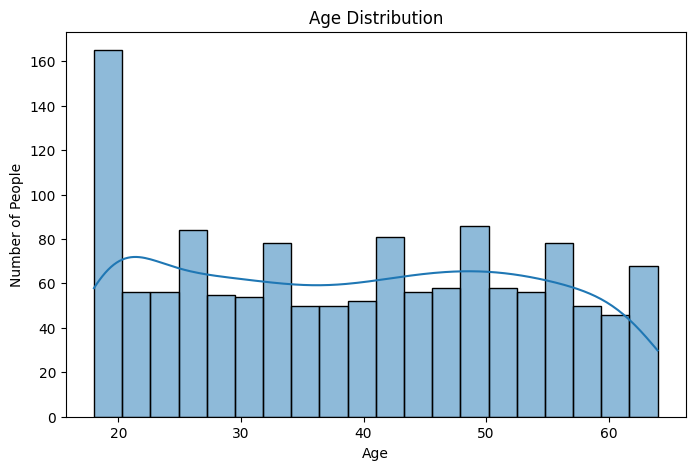

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['age'], bins=20, kde=True)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of People')

plt.show()

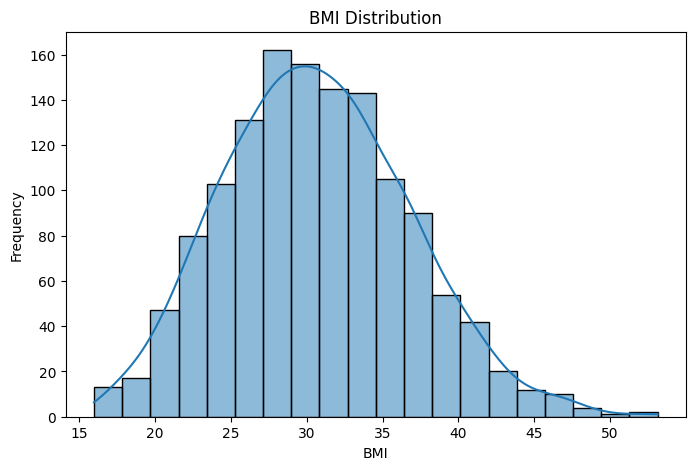

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['bmi'], bins=20, kde=True)

plt.title('BMI Distribution')
plt.xlabel('BMI')
plt.ylabel('Frequency')

plt.show()

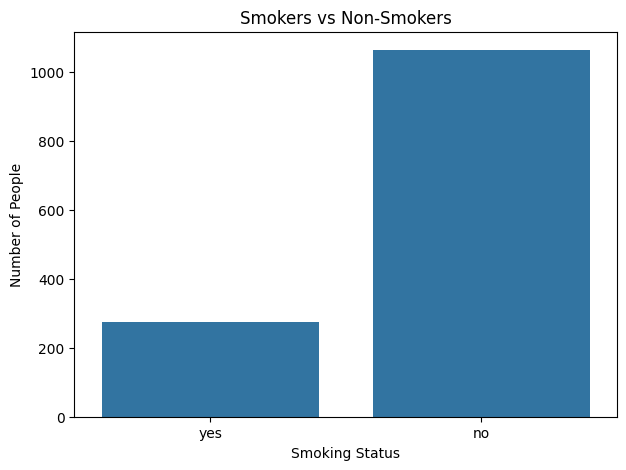

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x='smoker')

plt.title('Smokers vs Non-Smokers')
plt.xlabel('Smoking Status')
plt.ylabel('Number of People')

plt.show()

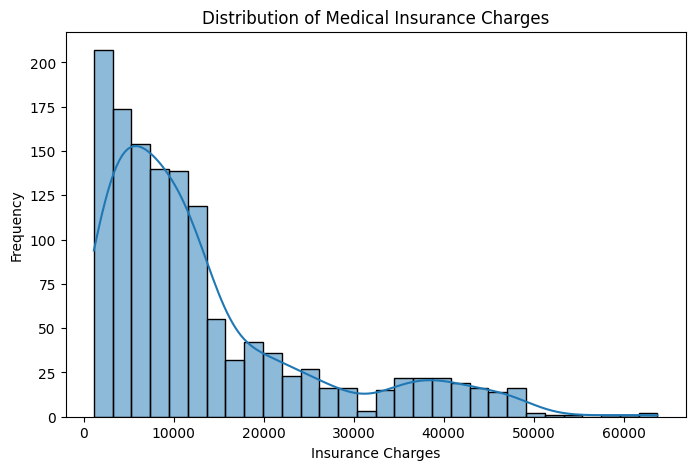

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['charges'], bins=30, kde=True)

plt.title('Distribution of Medical Insurance Charges')
plt.xlabel('Insurance Charges')
plt.ylabel('Frequency')

plt.show()

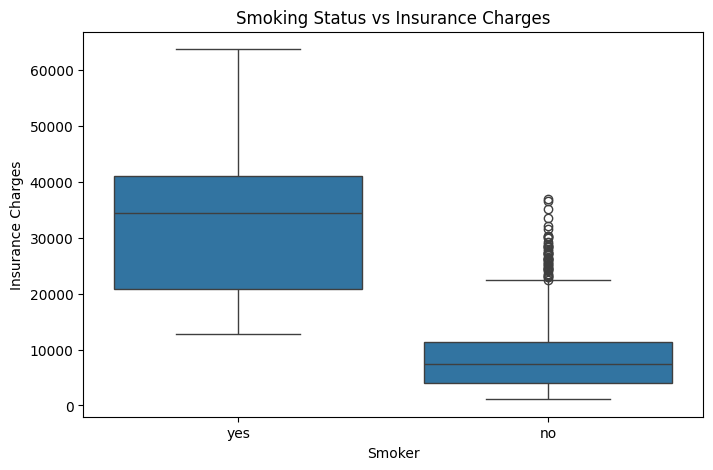

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x='smoker', y='charges')

plt.title('Smoking Status vs Insurance Charges')
plt.xlabel('Smoker')
plt.ylabel('Insurance Charges')

plt.show()

In [ ]:
# Convert categorical columns into numerical values
encoded_df = pd.get_dummies(
    df,
    columns=['sex', 'smoker', 'region'],
    drop_first=True,
    dtype=int
)

print("Encoded Dataset:")
print(encoded_df.head())

print("\nNew Columns:")
print(encoded_df.columns)

Encoded Dataset:
   age     bmi  children      charges  sex_male  smoker_yes  region_northwest  \
0   19  27.900         0  16884.92400         0           1                 0   
1   18  33.770         1   1725.55230         1           0                 0   
2   28  33.000         3   4449.46200         1           0                 0   
3   33  22.705         0  21984.47061         1           0                 1   
4   32  28.880         0   3866.85520         1           0                 1   

   region_southeast  region_southwest  
0                 0                 1  
1                 1                 0  
2                 1                 0  
3                 0                 0  
4                 0                 0  

New Columns:
Index(['age', 'bmi', 'children', 'charges', 'sex_male', 'smoker_yes',
       'region_northwest', 'region_southeast', 'region_southwest'],
      dtype='object')


In [ ]:
# Regression dataset
X_reg = encoded_df.drop(
    columns=['charges', 'smoker_yes']
)
X_reg['smoker_yes'] = encoded_df['smoker_yes']

y_reg = encoded_df['charges']

# Classification dataset
X_clf = encoded_df.drop(
    columns=['smoker_yes', 'charges']
)

y_clf = encoded_df['smoker_yes']

print("Regression Features:", X_reg.shape)
print("Regression Target:", y_reg.shape)

print("\nClassification Features:", X_clf.shape)
print("Classification Target:", y_clf.shape)

Regression Features: (1337, 8)
Regression Target: (1337,)

Classification Features: (1337, 7)
Classification Target: (1337,)


In [ ]:
from sklearn.model_selection import train_test_split

# Regression split
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# Classification split
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

print("Regression Training:", X_train_reg.shape)
print("Regression Testing:", X_test_reg.shape)

print("\nClassification Training:", X_train_clf.shape)
print("Classification Testing:", X_test_clf.shape)

Regression Training: (1069, 8)
Regression Testing: (268, 8)

Classification Training: (1069, 7)
Classification Testing: (268, 7)


In [ ]:
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import numpy as np
import pandas as pd

In [ ]:
# Create regression models
reg_models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(
        n_estimators=100, random_state=42
    )
}

# Train all regression models
for name, model in reg_models.items():
    model.fit(X_train_reg, y_train_reg)
    print(name, "trained successfully!")

Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [ ]:
reg_results = []

for name, model in reg_models.items():

    predictions = model.predict(X_test_reg)

    mae = mean_absolute_error(y_test_reg, predictions)
    mse = mean_squared_error(y_test_reg, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_reg, predictions)

    reg_results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

reg_results_df = pd.DataFrame(reg_results)

print(reg_results_df.round(2))

               Model      MAE          MSE     RMSE  R2 Score
0  Linear Regression  4177.05  35478020.68  5956.34      0.81
1      Decision Tree  2730.63  33281524.62  5769.01      0.82
2      Random Forest  2637.57  22105455.09  4701.64      0.88


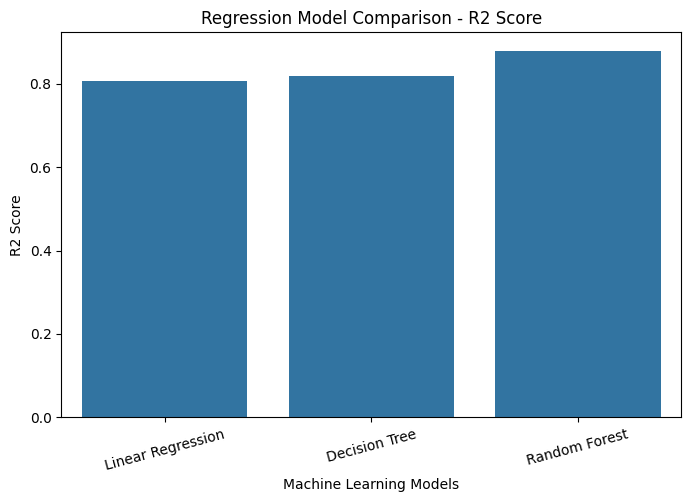

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=reg_results_df,
    x='Model',
    y='R2 Score'
)

plt.title('Regression Model Comparison - R2 Score')
plt.xlabel('Machine Learning Models')
plt.ylabel('R2 Score')
plt.xticks(rotation=15)

plt.show()

In [ ]:
# Create classification models
clf_models = {
    'Logistic Regression': make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    'Decision Tree': DecisionTreeClassifier(random_state=42),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    'KNN': make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )
}

# Train all classification models
for name, model in clf_models.items():
    model.fit(X_train_clf, y_train_clf)
    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
KNN trained successfully!


In [ ]:
clf_results = []

for name, model in clf_models.items():

    predictions = model.predict(X_test_clf)

    accuracy = accuracy_score(y_test_clf, predictions)
    precision = precision_score(
        y_test_clf, predictions, zero_division=0
    )
    recall = recall_score(
        y_test_clf, predictions, zero_division=0
    )
    f1 = f1_score(
        y_test_clf, predictions, zero_division=0
    )

    clf_results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

clf_results_df = pd.DataFrame(clf_results)

print(clf_results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.7948     0.0000  0.0000    0.0000
1        Decision Tree    0.6530     0.1607  0.1636    0.1622
2        Random Forest    0.7388     0.1429  0.0545    0.0789
3                  KNN    0.7537     0.1765  0.0545    0.0833


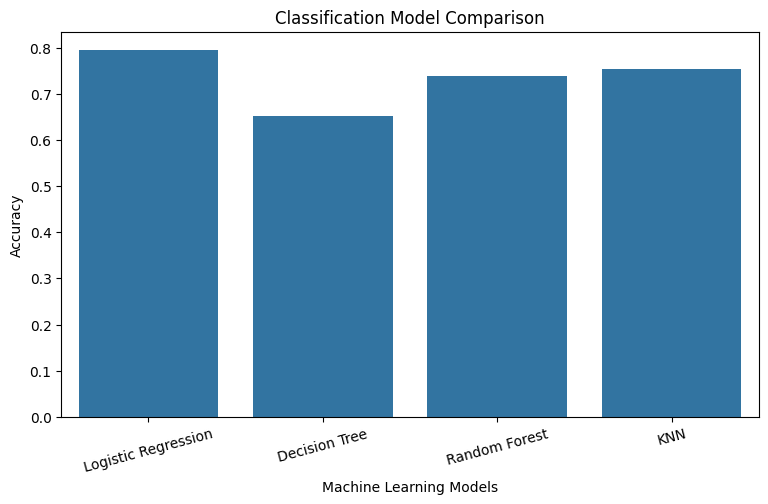

In [ ]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=clf_results_df,
    x='Model',
    y='Accuracy'
)

plt.title('Classification Model Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy')
plt.xticks(rotation=15)

plt.show()

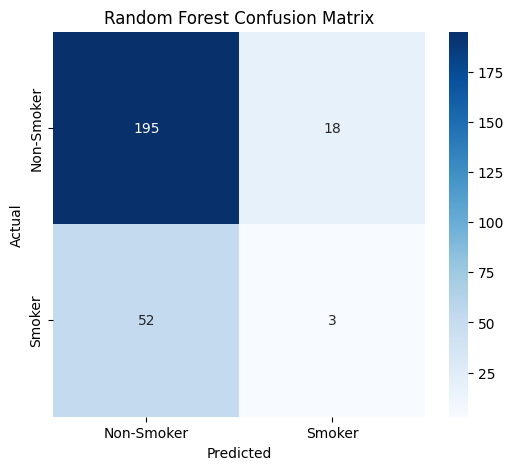

In [ ]:
rf_predictions = clf_models['Random Forest'].predict(X_test_clf)

cm = confusion_matrix(y_test_clf, rf_predictions)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Smoker', 'Smoker'],
    yticklabels=['Non-Smoker', 'Smoker']
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
reg_param_grids = {
    'Decision Tree': {
        'max_depth': [None, 5, 10, 15],
        'min_samples_split': [2, 5, 10]
    },

    'Random Forest': {
        'n_estimators': [100, 200],
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5]
    }
}

tuned_reg_models = {}

for name, params in reg_param_grids.items():

    grid = GridSearchCV(
        reg_models[name],
        params,
        cv=5,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1
    )

    grid.fit(X_train_reg, y_train_reg)

    tuned_reg_models[name] = grid.best_estimator_

    print("\n", name)
    print("Best Parameters:", grid.best_params_)
    print("Best CV RMSE:", -grid.best_score_)


 Decision Tree
Best Parameters: {'max_depth': 5, 'min_samples_split': 10}
Best CV RMSE: 4820.245700540512

 Random Forest
Best Parameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}
Best CV RMSE: 4847.002520886866


In [ ]:
clf_param_grids = {
    'Logistic Regression': {
        'logisticregression__C': [0.1, 1, 10]
    },

    'Decision Tree': {
        'max_depth': [None, 5, 10],
        'min_samples_split': [2, 5]
    },

    'Random Forest': {
        'n_estimators': [100, 200],
        'max_depth': [None, 10, 20]
    },

    'KNN': {
        'kneighborsclassifier__n_neighbors': [3, 5, 7, 9],
        'kneighborsclassifier__weights': ['uniform', 'distance']
    }
}

tuned_clf_models = {}

for name, params in clf_param_grids.items():

    grid = GridSearchCV(
        clf_models[name],
        params,
        cv=5,
        scoring='f1',
        n_jobs=-1
    )

    grid.fit(X_train_clf, y_train_clf)

    tuned_clf_models[name] = grid.best_estimator_

    print("\n", name)
    print("Best Parameters:", grid.best_params_)
    print("Best CV F1 Score:", grid.best_score_)


 Logistic Regression
Best Parameters: {'logisticregression__C': 0.1}
Best CV F1 Score: 0.0

 Decision Tree
Best Parameters: {'max_depth': None, 'min_samples_split': 2}
Best CV F1 Score: 0.24354496727339678

 Random Forest
Best Parameters: {'max_depth': None, 'n_estimators': 100}
Best CV F1 Score: 0.15446977426510525

 KNN
Best Parameters: {'kneighborsclassifier__n_neighbors': 3, 'kneighborsclassifier__weights': 'distance'}
Best CV F1 Score: 0.23762816131237186


In [ ]:
tuned_reg_results = []

for name, model in tuned_reg_models.items():

    predictions = model.predict(X_test_reg)

    mse = mean_squared_error(y_test_reg, predictions)

    tuned_reg_results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test_reg, predictions),
        'RMSE': np.sqrt(mse),
        'R2 Score': r2_score(y_test_reg, predictions)
    })

tuned_reg_df = pd.DataFrame(tuned_reg_results)

print(tuned_reg_df.round(3))

           Model       MAE      RMSE  R2 Score
0  Decision Tree  2656.839  4411.538     0.894
1  Random Forest  2580.219  4537.763     0.888


In [ ]:
tuned_clf_results = []

for name, model in tuned_clf_models.items():

    predictions = model.predict(X_test_clf)

    tuned_clf_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test_clf, predictions),
        'Precision': precision_score(
            y_test_clf, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_test_clf, predictions, zero_division=0
        ),
        'F1 Score': f1_score(
            y_test_clf, predictions, zero_division=0
        )
    })

tuned_clf_df = pd.DataFrame(tuned_clf_results)

print(tuned_clf_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.7948     0.0000  0.0000    0.0000
1        Decision Tree    0.6530     0.1607  0.1636    0.1622
2        Random Forest    0.7388     0.1429  0.0545    0.0789
3                  KNN    0.6903     0.1818  0.1455    0.1616


In [ ]:
comparison_reg = pd.concat([
    reg_results_df.assign(Stage='Before Tuning'),
    tuned_reg_df.assign(Stage='After Tuning')
], ignore_index=True)

print(comparison_reg.round(3))

               Model       MAE           MSE      RMSE  R2 Score  \
0  Linear Regression  4177.046  3.547802e+07  5956.343     0.807   
1      Decision Tree  2730.630  3.328152e+07  5769.014     0.819   
2      Random Forest  2637.566  2.210546e+07  4701.644     0.880   
3      Decision Tree  2656.839           NaN  4411.538     0.894   
4      Random Forest  2580.219           NaN  4537.763     0.888   

           Stage  
0  Before Tuning  
1  Before Tuning  
2  Before Tuning  
3   After Tuning  
4   After Tuning  


In [ ]:
comparison_clf = pd.concat([
    clf_results_df.assign(Stage='Before Tuning'),
    tuned_clf_df.assign(Stage='After Tuning')
], ignore_index=True)

print(comparison_clf.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score          Stage
0  Logistic Regression    0.7948     0.0000  0.0000    0.0000  Before Tuning
1        Decision Tree    0.6530     0.1607  0.1636    0.1622  Before Tuning
2        Random Forest    0.7388     0.1429  0.0545    0.0789  Before Tuning
3                  KNN    0.7537     0.1765  0.0545    0.0833  Before Tuning
4  Logistic Regression    0.7948     0.0000  0.0000    0.0000   After Tuning
5        Decision Tree    0.6530     0.1607  0.1636    0.1622   After Tuning
6        Random Forest    0.7388     0.1429  0.0545    0.0789   After Tuning
7                  KNN    0.6903     0.1818  0.1455    0.1616   After Tuning


In [ ]:
# Select best regression model
reg_candidates = reg_models.copy()
reg_candidates.update(tuned_reg_models)

best_reg_name = min(
    reg_candidates,
    key=lambda name: np.sqrt(
        mean_squared_error(
            y_test_reg,
            reg_candidates[name].predict(X_test_reg)
        )
    )
)

best_reg_model = reg_candidates[best_reg_name]

# Select best classification model
clf_candidates = clf_models.copy()
clf_candidates.update(tuned_clf_models)

best_clf_name = max(
    clf_candidates,
    key=lambda name: f1_score(
        y_test_clf,
        clf_candidates[name].predict(X_test_clf),
        zero_division=0
    )
)

best_clf_model = clf_candidates[best_clf_name]

print("Best Regression Model:", best_reg_name)
print("Best Classification Model:", best_clf_name)

Best Regression Model: Decision Tree
Best Classification Model: Decision Tree


In [ ]:
def predict_insurance(age, sex, bmi, children,
                      smoker, region):

    # Prepare user input
    user_data = pd.DataFrame([{
        'age': age,
        'bmi': bmi,
        'children': children,
        'sex_male': 1 if sex.lower() == 'male' else 0,
        'smoker_yes': 1 if smoker.lower() == 'yes' else 0,
        'region_northwest': 1 if region == 'northwest' else 0,
        'region_southeast': 1 if region == 'southeast' else 0,
        'region_southwest': 1 if region == 'southwest' else 0
    }])

    # Regression prediction
    reg_input = user_data.reindex(
        columns=X_train_reg.columns,
        fill_value=0
    )

    predicted_charges = best_reg_model.predict(reg_input)[0]

    # Classification prediction
    clf_input = user_data.drop(
        columns=['smoker_yes']
    ).reindex(
        columns=X_train_clf.columns,
        fill_value=0
    )

    smoker_prediction = best_clf_model.predict(clf_input)[0]

    print("\n========== PREDICTION RESULTS ==========")

    print("Predicted Insurance Charges: $",
          round(predicted_charges, 2))

    print("Predicted Smoker Status:",
          "Smoker" if smoker_prediction == 1
          else "Non-Smoker")

    print("========================================")

In [ ]:
predict_insurance(
    age=25,
    sex='female',
    bmi=27.5,
    children=0,
    smoker='no',
    region='southeast'
)


========== PREDICTION RESULTS ==========
Predicted Insurance Charges: $ 4325.86
Predicted Smoker Status: Non-Smoker


In [ ]:
import joblib

# Save best regression model
joblib.dump(
    best_reg_model,
    'best_insurance_model.pkl'
)

# Save best classification model
joblib.dump(
    best_clf_model,
    'best_smoker_model.pkl'
)

print("Models saved successfully!")

Models saved successfully!


In [ ]:
from google.colab import files

files.download('best_insurance_model.pkl')
files.download('best_smoker_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import joblib

# Create a complete project bundle
project_bundle = {
    'best_reg_model': best_reg_model,
    'best_clf_model': best_clf_model,

    'best_reg_name': best_reg_name,
    'best_clf_name': best_clf_name,

    'reg_models': reg_candidates,
    'clf_models': clf_candidates,

    'reg_results': reg_results_df,
    'clf_results': clf_results_df,

    'tuned_reg_results': tuned_reg_df,
    'tuned_clf_results': tuned_clf_df,

    'reg_columns': list(X_train_reg.columns),
    'clf_columns': list(X_train_clf.columns),

    'dataset': df
}

# Save everything in one file
joblib.dump(project_bundle, 'insurance_project_bundle.pkl')

print("Project bundle created successfully!")

Project bundle created successfully!


In [ ]:
from google.colab import files

files.download('insurance_project_bundle.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>